In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## adjusting the title to the imagle as groups in Training

In [2]:
import os

folder = r"C:\Users\harsh\Downloads\AI-ML-DL\Kaggle\xray_dataset_covid19 -- CNN\train"

file_paths_train = []
labels_train = []

folders = os.listdir(folder)

for fold in folders:
    fold_path = os.path.join(folder, fold)

    if os.path.isdir(fold_path):
        files = os.listdir(fold_path)

        for file in files:
            file_path = os.path.join(fold_path, file)

            file_paths_train.append(file_path)
            labels_train.append(fold)

print("Total images:", len(file_paths_train))
print("Total labels:", len(labels_train))

Total images: 148
Total labels: 148


## adjusting the title to the imagle as groups for Testing

In [3]:
folder_path=r"C:\Users\harsh\Downloads\AI-ML-DL\Kaggle\xray_dataset_covid19 -- CNN\test"
file_paths_test=[]
labels_test=[]
foldes=os.listdir(folder_path)
for fold in foldes:
    fold_path=os.path.join(folder_path,fold)
    folders=os.listdir(fold_path)
    for file in folders:
        file_path=os.path.join(fold_path,file)
        file_paths_test.append(file_path)
        labels_test.append(fold)

In [4]:
df_train=pd.DataFrame({'file_paths':file_paths_train,'labels':labels_train})


In [5]:
df_train


,file_paths,labels
0,C:\Users\harsh\Downloads\AI-ML-DL\Kaggle\xray_...,NORMAL
1,C:\Users\harsh\Downloads\AI-ML-DL\Kaggle\xray_...,NORMAL
2,C:\Users\harsh\Downloads\AI-ML-DL\Kaggle\xray_...,NORMAL
3,C:\Users\harsh\Downloads\AI-ML-DL\Kaggle\xray_...,NORMAL
4,C:\Users\harsh\Downloads\AI-ML-DL\Kaggle\xray_...,NORMAL
...,...,...
143,C:\Users\harsh\Downloads\AI-ML-DL\Kaggle\xray_...,PNEUMONIA
144,C:\Users\harsh\Downloads\AI-ML-DL\Kaggle\xray_...,PNEUMONIA
145,C:\Users\harsh\Downloads\AI-ML-DL\Kaggle\xray_...,PNEUMONIA
146,C:\Users\harsh\Downloads\AI-ML-DL\Kaggle\xray_...,PNEUMONIA


In [6]:
df_test=pd.DataFrame({'file_paths':file_paths_test,'labels':labels_test})


In [7]:
import tensorflow as tf
from tensorflow.keras.preprocessing import image
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import Conv2D,MaxPooling2D,Flatten,Dense
from tensorflow.keras.models import Sequential
from sklearn.model_selection import train_test_split
gen=ImageDataGenerator()
train_gen=gen.flow_from_dataframe(df_train,x_col='file_paths',y_col='labels',target_size=(224,224)
                                  ,class_mode='categorical',batch_size=16)
test_gen=gen.flow_from_dataframe(df_test,x_col='file_paths',y_col='labels',target_size=(224,224)
                                  ,class_mode='categorical',batch_size=16)

Found 148 validated image filenames belonging to 2 classes.
Found 40 validated image filenames belonging to 2 classes.


## Creating the model

In [8]:
model=Sequential([
    Conv2D(256,(3,3),input_shape=(224,224,3),activation='relu'),MaxPooling2D((2,2)),
    Conv2D(128,(3,3),activation='relu'),MaxPooling2D((2,2)),
    Conv2D(64,(3,3),activation='relu'),MaxPooling2D((2,2)),
    Flatten(),
    Dense(256,activation='relu'),
    Dense(128,activation='relu'),
    Dense(64,activation='relu'),
    Dense(2,activation='softmax')
])
model.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])

C:\Users\harsh\anaconda3\envs\pythonenvironment\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [9]:
model.fit(train_gen,epochs=10)


Epoch 1/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 100s 10s/step - accuracy: 0.6081 - loss: 52.5247
Epoch 2/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 97s 9s/step - accuracy: 0.6486 - loss: 1.9591
Epoch 3/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 94s 9s/step - accuracy: 0.9324 - loss: 0.4253
Epoch 4/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 138s 9s/step - accuracy: 0.9054 - loss: 0.3585
Epoch 5/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 84s 8s/step - accuracy: 0.8784 - loss: 0.4234
Epoch 6/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 140s 8s/step - accuracy: 0.9595 - loss: 0.1458
Epoch 7/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 83s 8s/step - accuracy: 0.9527 - loss: 0.0947
Epoch 8/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 89s 9s/step - accuracy: 0.9527 - loss: 0.1931
Epoch 9/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 84s 8s/step - accuracy: 0.9527 - loss: 0.1477
Epoch 10/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 80s 8s/step - accuracy: 0.9662 - loss: 0.1275


In [10]:
model.evaluate(train_gen)


10/10 ━━━━━━━━━━━━━━━━━━━━ 20s 2s/step - accuracy: 0.9392 - loss: 0.1459


[0.14592072367668152, 0.9391891956329346]

In [11]:
model.evaluate(test_gen)


3/3 ━━━━━━━━━━━━━━━━━━━━ 6s 2s/step - accuracy: 0.9500 - loss: 0.1534


[0.1534217894077301, 0.949999988079071]

In [12]:
img_path=r"C:\Users\harsh\Downloads\AI-ML-DL\Kaggle\xray_dataset_covid19 -- CNN\train\PNEUMONIA\lancet-case2a.jpg"
img=image.load_img(img_path,target_size=(224,224))
img_arry=image.img_to_array(img)
img_arry=img_arry/255.0
img_batch=np.expand_dims(img_arry,axis=0)

In [13]:
fols=os.listdir(r"C:\Users\harsh\Downloads\AI-ML-DL\Kaggle\xray_dataset_covid19 -- CNN\train")
fols[1]



'PNEUMONIA'

In [14]:
predictions = model.predict(img_batch)

predicted_class_indices = np.argmax(predictions, axis=1)

labels = {0: fols[0], 1:fols[1]}
result = labels[predicted_class_indices[0]]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 620ms/step


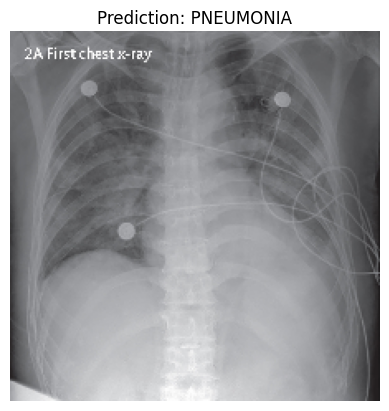

In [15]:
plt.imshow(img)
plt.title(f"Prediction: {result}")
plt.axis('off')
plt.show()

## accuracy testing 

In [16]:
test_loss, test_accuracy = model.evaluate(test_gen)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 1s/step - accuracy: 0.9500 - loss: 0.1534
Test Loss: 0.1534217894077301
Test Accuracy: 94.9999988079071 %


In [17]:
model.save("pneumonia_cnn_model.keras")